# Exploratory Data Analysis — NCAA Four Factors (2003–2025)

ECE 3308 · Texas Tech University

Which of Dean Oliver's Four Factors best explains who wins a college basketball game? Each row of the
Master Analytical Table is one Division I men's game (all regular-season games 2003–2025 plus
tournaments 2003–2024). Team A and Team B are assigned at random, and each feature is **Team A minus
Team B** for that game:

| Feature | Meaning |
|---|---|
| `DIFF_EFG` | effective field goal % — (FGM + 0.5·3PM) / FGA |
| `DIFF_TOV` | turnovers per 100 possessions |
| `DIFF_ORB` | offensive rebound rate — OR / (OR + opponent DR) |
| `DIFF_FTR` | free throw rate — FTA / FGA |

`Win_A` is 1 if Team A won. Three questions:

1. Which factor has the strongest relationship with winning?
2. Do the factors visually separate winners from losers?
3. Do tournament seeds line up with results, and what happens in the biggest upsets?

Run `python build_master_table.py` first to create `data/Master_Analytical_Table.csv`.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import pandas as pd
from ncaa_ff import FEATURES, data, eda

DATA = Path.cwd().parent / "data"
table = pd.read_csv(DATA / "Master_Analytical_Table.csv")
print(f"{len(table):,} games, seasons {table.Season.min()}-{table.Season.max()}, "
      f"Win_A = 1 in {table.Win_A.mean():.1%}")
table[FEATURES].describe().round(4)

120,264 games, seasons 2003-2025, Win_A = 1 in 49.8%


,DIFF_EFG,DIFF_TOV,DIFF_ORB,DIFF_FTR
count,120264.0000,120264.0000,120264.0000,120264.0000
mean,-0.0004,0.0298,-0.0009,-0.0001
std,0.1263,7.5794,0.1343,0.2169
min,-0.5250,-41.5958,-0.6000,-1.3468
25%,-0.0861,-4.9923,-0.0905,-0.1391
50%,-0.0004,0.0166,0.0000,0.0000
75%,0.0849,5.0379,0.0886,0.1389
max,0.5330,41.2341,0.6555,1.3442


## Dataset overview

The table holds 120,264 games and is balanced (about half wins, half losses) because the winner is
randomly placed on side A or B. Every differential averages roughly zero, which confirms the random
assignment. The spreads are large, especially for turnover rate and free throw rate, so single
games vary a lot.

DIFF_EFG    0.660
DIFF_TOV   -0.245
DIFF_ORB    0.254
DIFF_FTR    0.396
Name: Win_A, dtype: float64

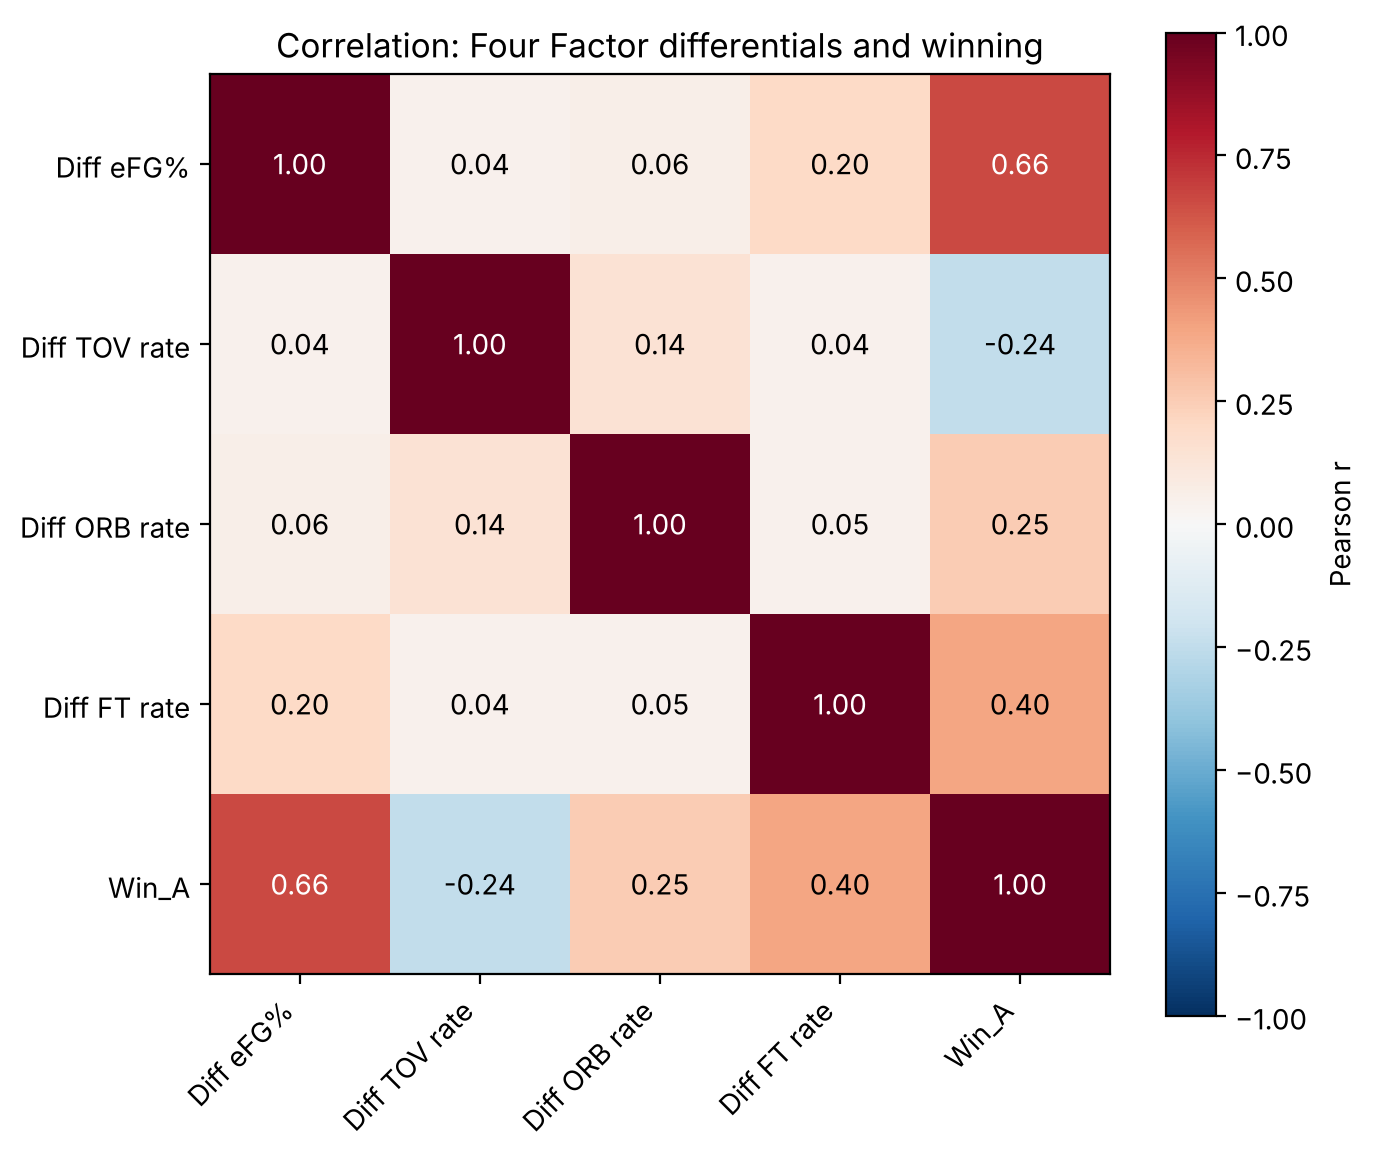

In [2]:
corr, _ = eda.correlation_matrix(table)
corr["Win_A"].drop("Win_A").round(3)

## Correlation analysis

**Shooting efficiency dominates:** `DIFF_EFG` has the strongest correlation with winning (r ≈ 0.66).
Free throw rate is next (r ≈ 0.40), then offensive rebounding (r ≈ 0.25). Turnover rate is
negatively correlated (r ≈ −0.24), as expected: turning the ball over more than the opponent costs
games. The four differentials are only weakly correlated with each other (|r| ≤ 0.20), so each one
carries mostly separate information.

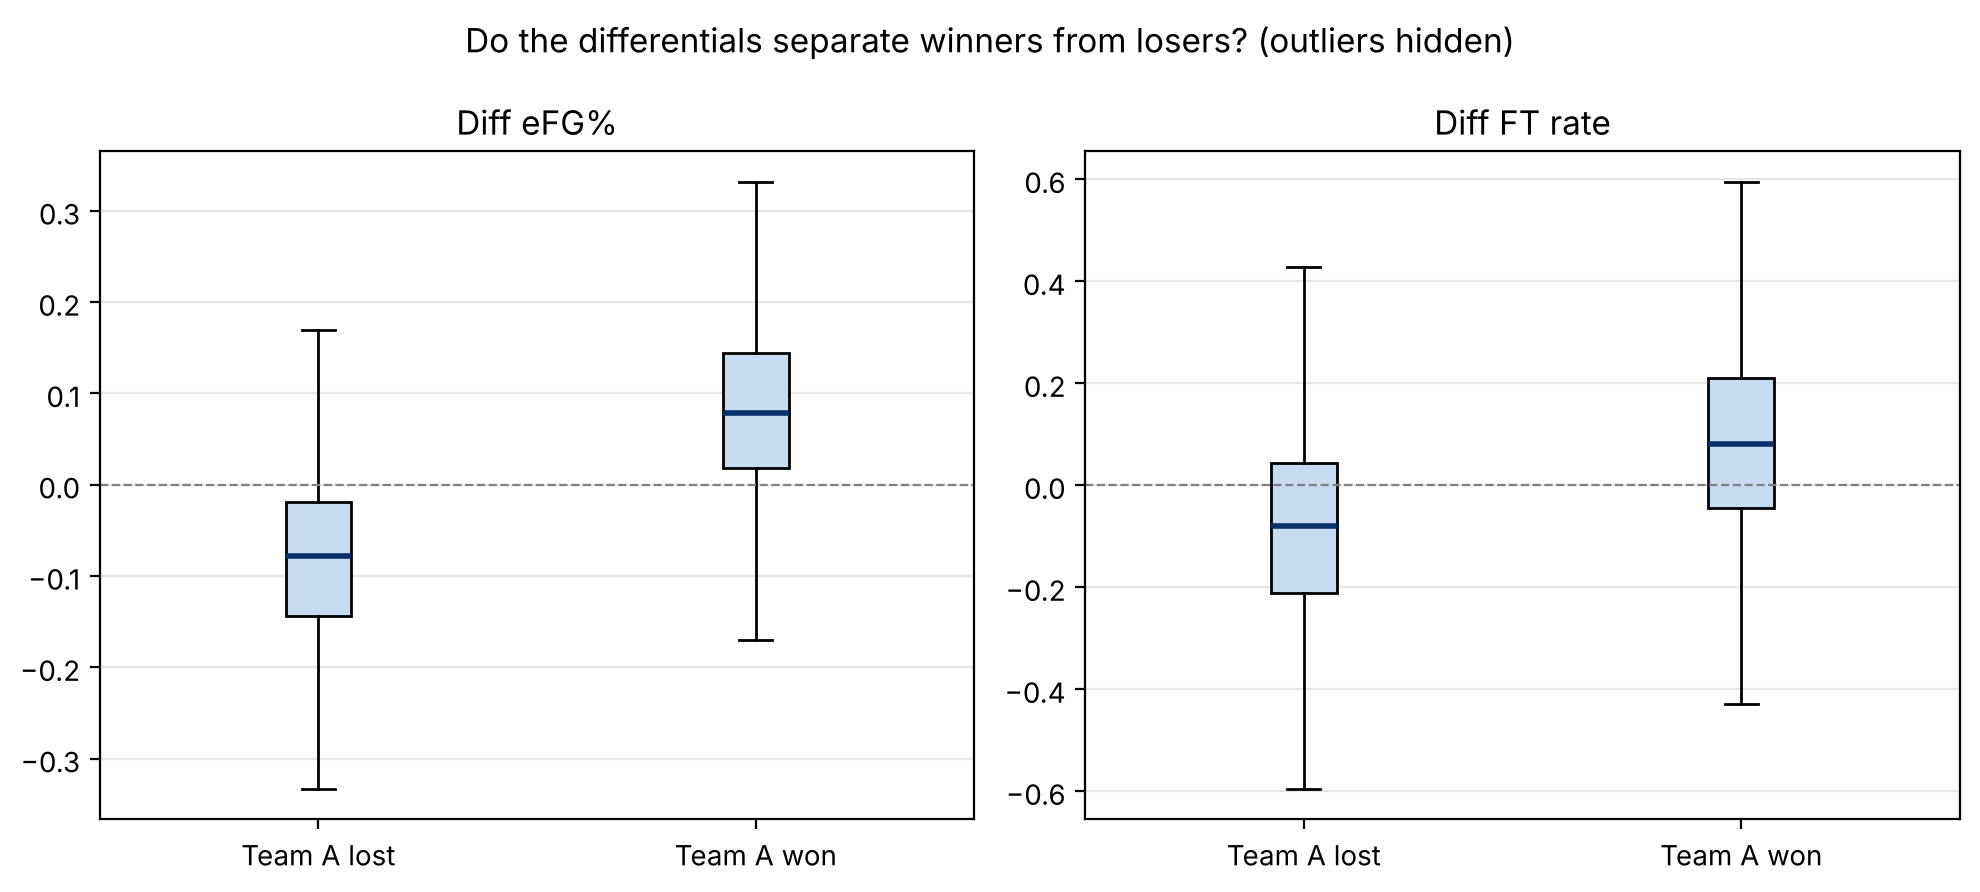

In [3]:
eda.separation_boxplots(table);

## Feature separation

The box plots compare the two strongest features for games Team A won and lost. `DIFF_EFG`
separates them clearly: the median is positive for wins and negative for losses, with little
overlap between the middle halves. `DIFF_FTR` points the same way but overlaps much more, so it
discriminates less well on its own, consistent with its moderate correlation.

1,382 tournament games; the winner was the worse seed in 27.6% of them


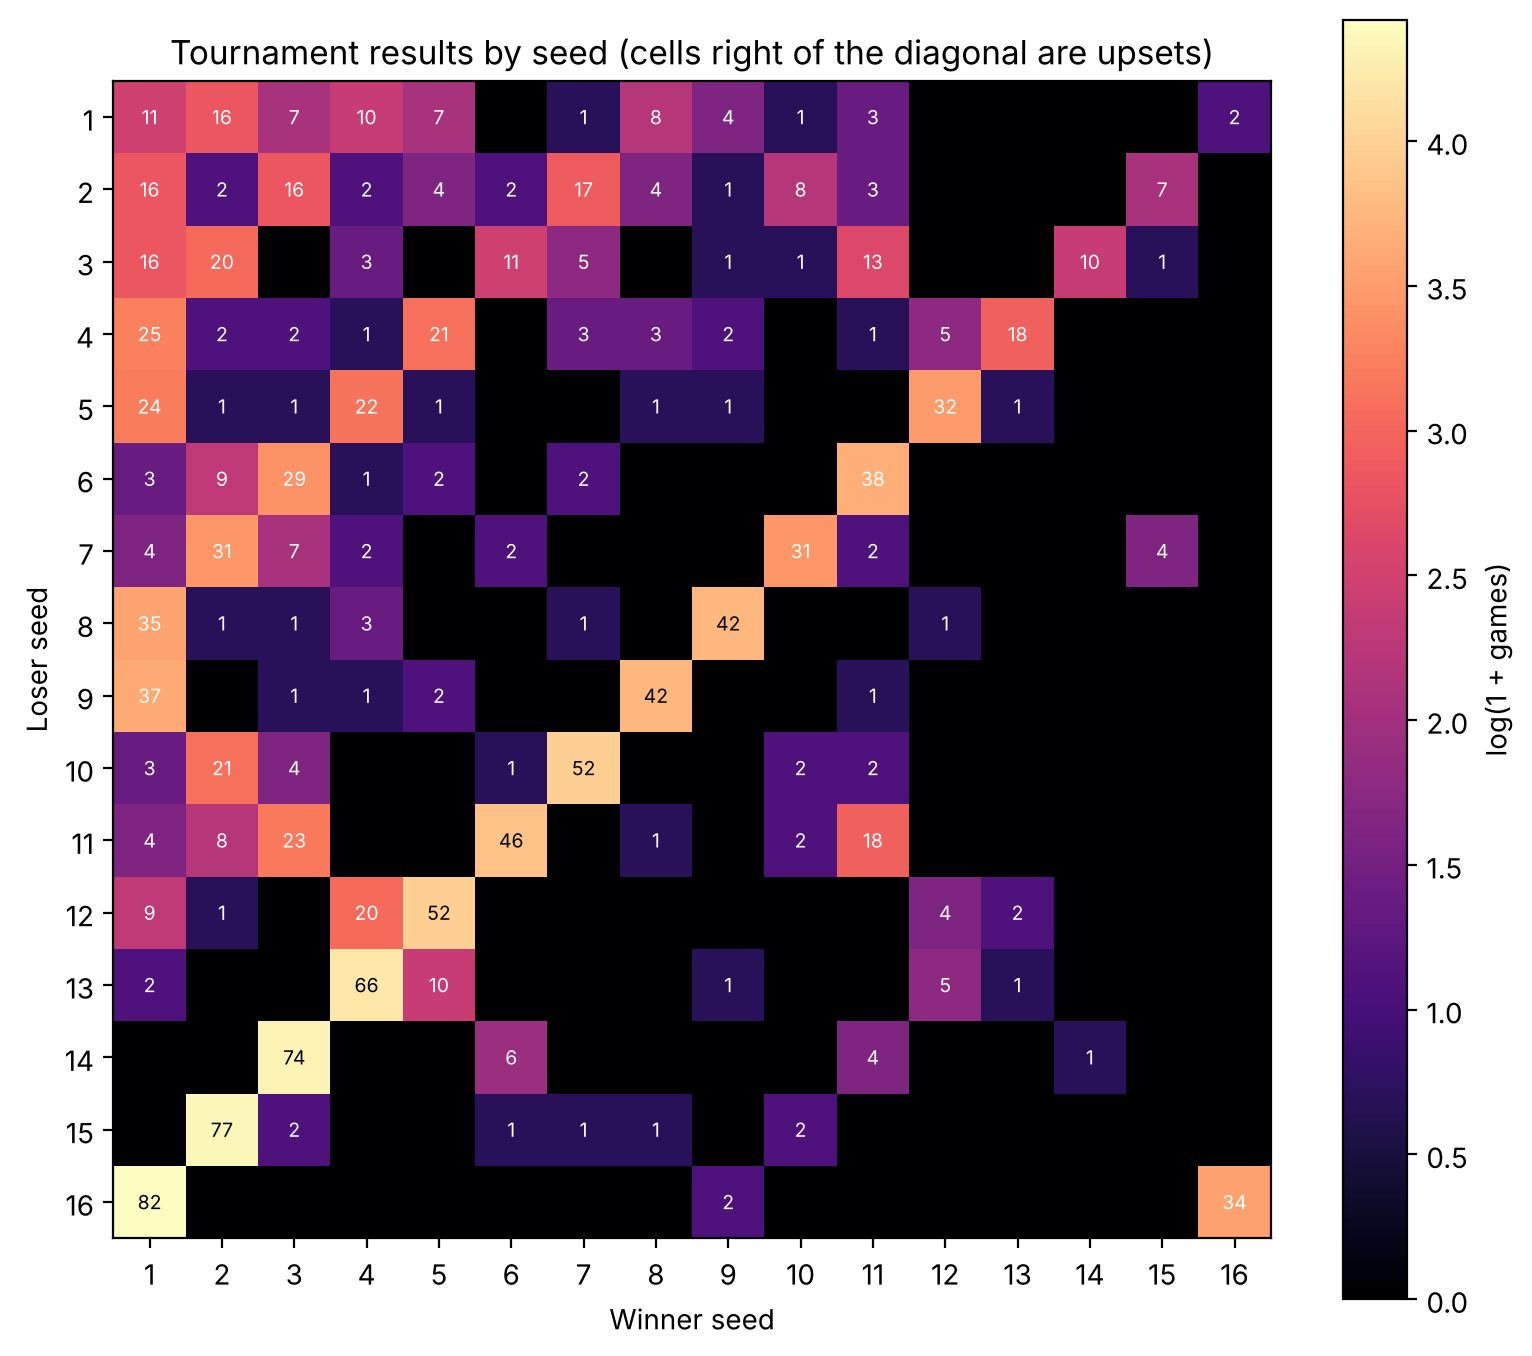

In [4]:
tourney = data.load("MNCAATourneyDetailedResults.csv", DATA)
tourney = tourney[tourney.Season < table.Season.max()]
seed_games = eda.tourney_seed_games(tourney, data.load("MNCAATourneySeeds.csv", DATA))
counts, _ = eda.seed_heatmap(seed_games)
print(f"{len(seed_games):,} tournament games; the winner was the worse seed in "
      f"{(seed_games.SeedDiff > 0).mean():.1%} of them")

## Seed heatmap

Each cell counts tournament games by winner seed (x) and loser seed (y). The bright cells along the
first-round pairings (1 vs 16, 2 vs 15 … 8 vs 9) show that the better seed usually wins. Cells to the
right of the diagonal, where the winner had the worse seed, are upsets: they are much darker, so
upsets are rare. The 16-vs-16 and 11-vs-11 cells are First Four play-in games between teams that
share a seed.

In [5]:
upsets = eda.biggest_upsets(seed_games)
names = data.team_names(DATA)
upsets.assign(Winner=upsets.WTeamID.map(names), Loser=upsets.LTeamID.map(names))[
    ["Season", "Winner", "WinnerSeed", "Loser", "LoserSeed"]
    + [c for c in upsets.columns if c.endswith("(W-L)")]
].round(3)

,Season,Winner,WinnerSeed,Loser,LoserSeed,DIFF_EFG (W-L),DIFF_TOV (W-L),DIFF_ORB (W-L),DIFF_FTR (W-L)
1014,2018,UMBC,16,Virginia,1,0.220,7.827,0.043,0.149
1271,2023,F Dickinson,16,Purdue,1,0.038,-11.704,-0.102,-0.197
605,2012,Lehigh,15,Duke,2,0.015,-7.195,-0.105,0.315
608,2012,Norfolk St,15,Missouri,2,-0.018,4.556,0.204,-0.004
668,2013,FGCU,15,Georgetown,2,0.060,-1.173,-0.056,0.585


## Upset autopsy

Only two 16-seeds have ever beaten a 1-seed, and both are in the data.

**UMBC over Virginia (2018).** UMBC shot far better than Virginia (Diff eFG **+0.220**). It actually
turned the ball over *more* (Diff TOV +7.8), but out-rebounded Virginia (+0.043) and got to the free
throw line much more (+0.149). That win came from shooting.

**Fairleigh Dickinson over Purdue (2023).** This one is the opposite. FDU's shooting edge was small
(+0.038), and it lost the rebounding (−0.102) and free throw (−0.197) battles. It won by forcing
turnovers: Diff TOV **−11.7**, meaning about 12 fewer turnovers per 100 possessions than Purdue.

So the biggest upsets aren't all explained by shooting alone. That's a good argument for keeping all
four factors in the model.

## Summary

- `DIFF_EFG` is the strongest single predictor of winning (r ≈ 0.66) and separates wins from losses
  most clearly.
- `DIFF_FTR` adds secondary value (r ≈ 0.40); `DIFF_ORB` (0.25) and `DIFF_TOV` (−0.24) are weaker
  alone but not noise.
- Seeds track tournament results closely, and upsets are rare.
- The two 16-over-1 upsets were won in different ways: UMBC through shooting, FDU through turnovers.

All four factors go into the logistic regression in `simulate_tournament.py`.